In [8]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap
from sklearn import datasets, model_selection

from ml import *


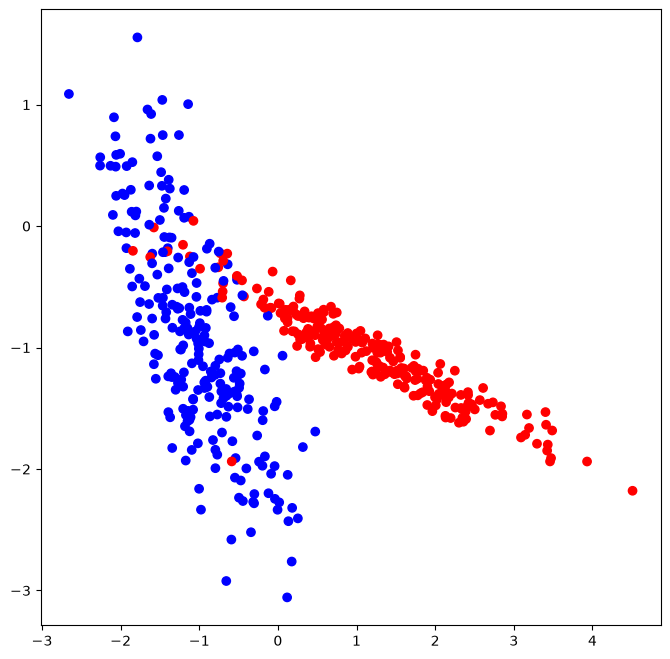

In [9]:
X, y = datasets.make_classification(n_samples=500,
                                                      n_features = 2, n_informative = 2,
                                                      n_classes = 2, n_redundant=0,
                                                      n_clusters_per_class=1, random_state=23)
colors = ListedColormap(['red', 'blue'])
light_colors = ListedColormap(['lightcoral', 'lightblue'])

plt.figure(figsize=(8,8))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=colors)

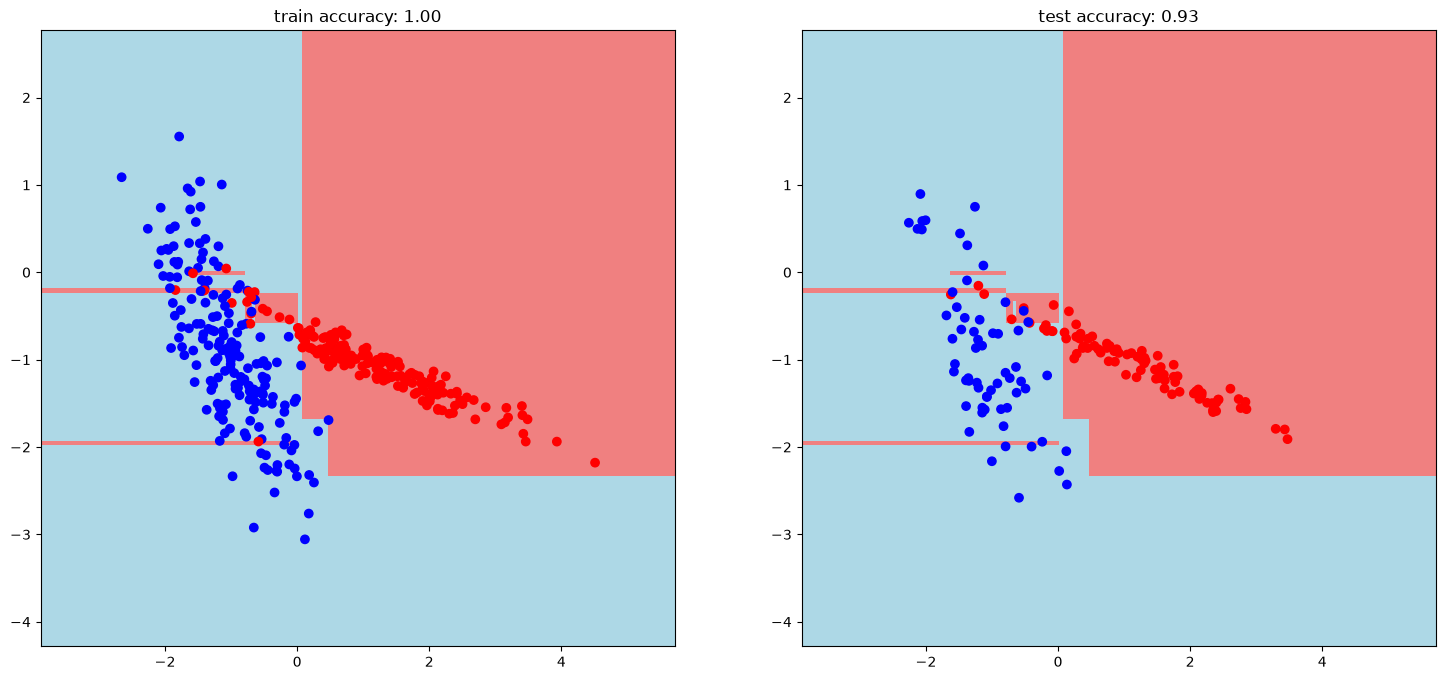

In [10]:
def get_meshgrid(X, step=0.05, border=1.2):
    x_min, x_max = X[:, 0].min() - border, X[:, 0].max() + border
    y_min, y_max = X[:, 1].min() - border, X[:, 1].max() + border
    return np.meshgrid(
        np.arange(x_min, x_max, step), np.arange(y_min, y_max, step)
    )

X_train, X_test, y_train, y_test = model_selection.train_test_split(X, y, test_size = 0.3, random_state = 1)

tree = DecisionTreeClassifier().fit(X_train, y_train)
forest = RandomForestClassifier(n_estimators=100).fit(X_train, y_train)

tree_train_pred = tree.predict(X_train)
tree_test_pred = tree.predict(X_test)

forest_train_pred = forest.predict(X_train)
forest_test_pred = forest.predict(X_test)

xx, yy = get_meshgrid(X)
grid_points = np.c_[xx.ravel(), yy.ravel()]

tree_mesh_preds = tree.predict(grid_points).reshape(xx.shape)
forest_mesh_preds = forest.predict(grid_points).reshape(xx.shape)

plt.figure(figsize=(18, 8))

plt.subplot(1, 2, 1)
plt.pcolormesh(xx, yy, tree_mesh_preds, cmap=light_colors)
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=colors)
plt.title(f'train accuracy: {tree.score(X_train, y_train):.2f}')

plt.subplot(1, 2, 2)
plt.pcolormesh(xx, yy, tree_mesh_preds, cmap=light_colors)
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap=colors)
plt.title(f'test accuracy: {tree.score(X_test, y_test):.2f}')

plt.show()

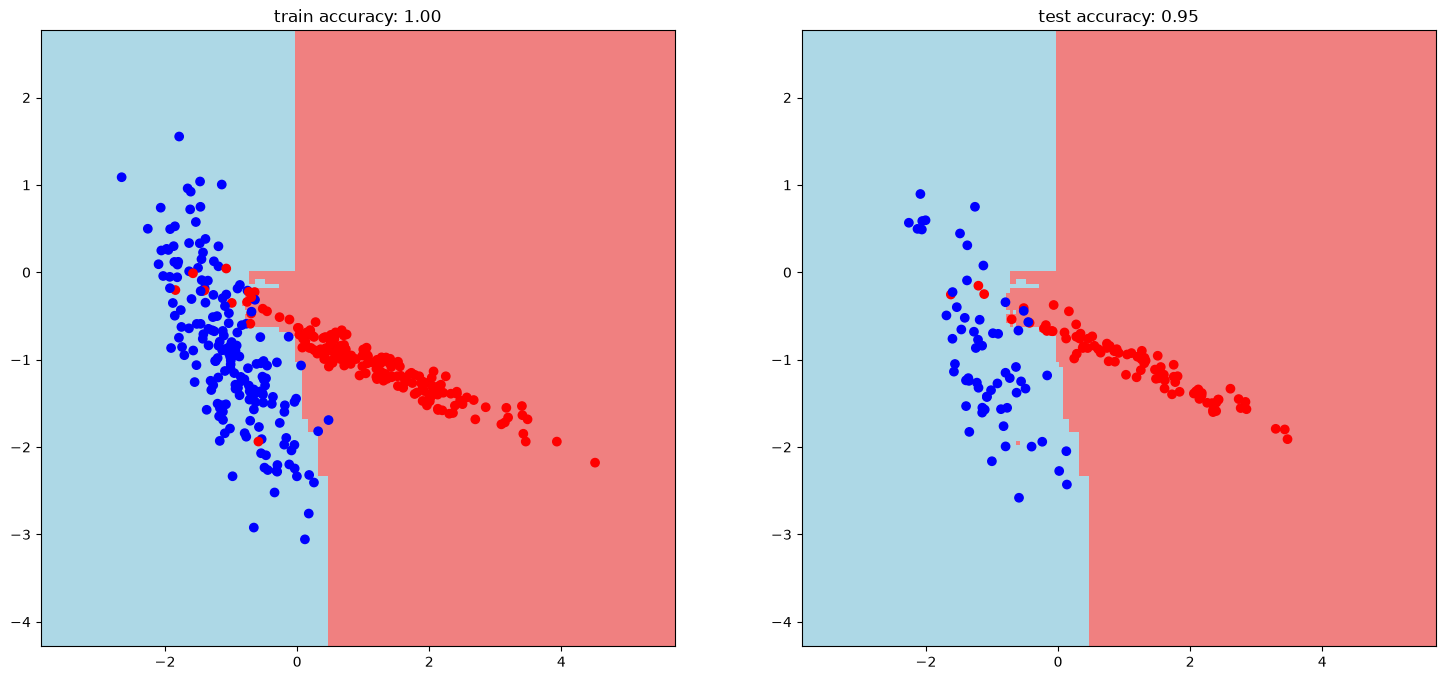

In [11]:
plt.figure(figsize=(18, 8))

plt.subplot(1, 2, 1)
plt.pcolormesh(xx, yy, forest_mesh_preds, cmap=light_colors)
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=colors)
plt.title(f'train accuracy: {forest.score(X_train, y_train):.2f}')

plt.subplot(1, 2, 2)
plt.pcolormesh(xx, yy, forest_mesh_preds, cmap=light_colors)
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap=colors)
plt.title(f'test accuracy: {forest.score(X_test, y_test):.2f}')

plt.show()